# Building a Basic Chatbot with LangGraph

In [2]:
from typing import Annotated
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import  add_messages #reducer

## State Declaration

In [ ]:
class State(TypedDict):
    messages: Annotated[list, add_messages]

## Loading the Environment Variables

In [5]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [6]:
from langchain.chat_models import init_chat_model

In [7]:
from langchain_openai import ChatOpenAI

## Initializing the LLM

In [8]:
llm = ChatOpenAI(
    model = "gpt-5",
    temperature = 0
)

## Chatbot function for node

In [9]:
def chatbot(state: State):
    return {"messages": [llm.invoke(state["messages"])]}

## Creating an instance of Graph Builder Class

In [11]:
graph_builder = StateGraph(State)

Initializing nodes and adding edges to graph

In [12]:
graph_builder.add_node("Chatbot", chatbot)

graph_builder.add_edge(START, "Chatbot")
graph_builder.add_edge("Chatbot", END)

graph = graph_builder.compile()

Visual of graph workflow

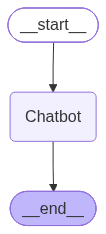

In [13]:
graph

## Testing the Graph

In [14]:
graph.invoke({"messages": "hELLO wORLD!"})

{'messages': [HumanMessage(content='hELLO wORLD!', additional_kwargs={}, response_metadata={}, id='d8fe11a0-a797-4aaf-a3c3-cd1e893dd0e5'),
  AIMessage(content='Hello! How can I help you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 146, 'prompt_tokens': 12, 'total_tokens': 158, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 128, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-5-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-E2w5f92Kmx849W6OjpnvtCSjhz0tc', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019f74a8-e8af-72c2-9778-c7fd39441707-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 12, 'output_tokens': 146, 'total_tokens': 158, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': 

In [ ]:
response = graph.invoke({'messages': "What do you think about garfield the cat?"})